# End-to-End MLOps: UCI Heart Disease Classification

This notebook reads the official UCI ZIP archive into memory and parses the Cleveland dataset directly from it. No raw dataset CSV is saved.

Includes EDA, Logistic Regression and Random Forest, cross-validation, MLflow, model packaging, sample inference, and tests. 

In [1]:
from pathlib import Path
import os, sys, subprocess
PROJECT_DIR = Path(r"C:\Users\rranj\MLOps_project\mlops_heart_disease_assignment_2")
SRC_DIR = PROJECT_DIR / "src"
sys.path.insert(0, str(SRC_DIR))
print("Project exists:", PROJECT_DIR.exists())
print("SRC_DIR exists:", (SRC_DIR).exists())
print("heartml exists:", (SRC_DIR / "heartml").exists())
print("Project dir:", PROJECT_DIR.resolve())
subprocess.check_call([sys.executable, "-m", "pip", "install", "-e", str(PROJECT_DIR)])


Project exists: True
SRC_DIR exists: True
heartml exists: True
Project dir: C:\Users\rranj\MLOps_project\mlops_heart_disease_assignment_2


0

## 1. Load dataset into memory (no CSV)

In [2]:
import pandas as pd
from heartml.data import load_uci_cleveland, FEATURES, TARGET
df = load_uci_cleveland()
print("Shape:", df.shape)
display(df.head())
display(df.isna().sum().to_frame("missing values"))
display(df[TARGET].value_counts().to_frame("count"))


Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


,missing values
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


,count
target,
0,164
1,139


## 2. EDA

artifacts\class_balance.png


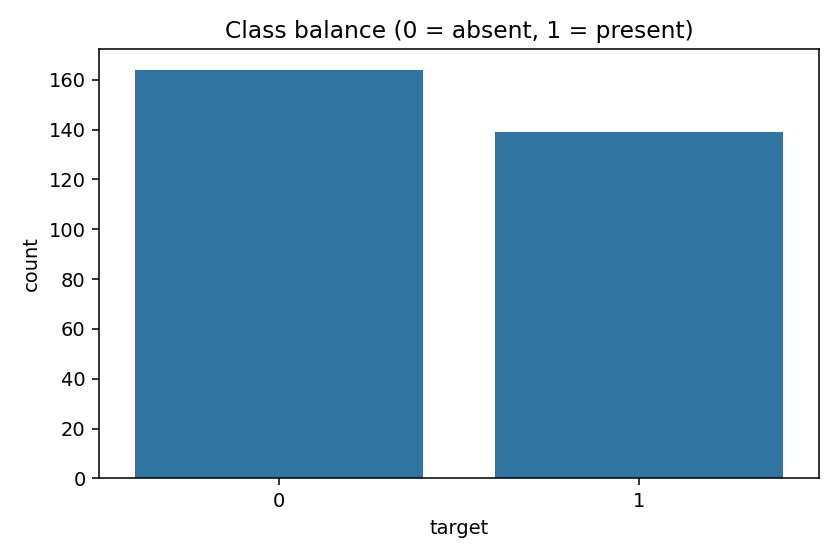

artifacts\feature_histograms.png


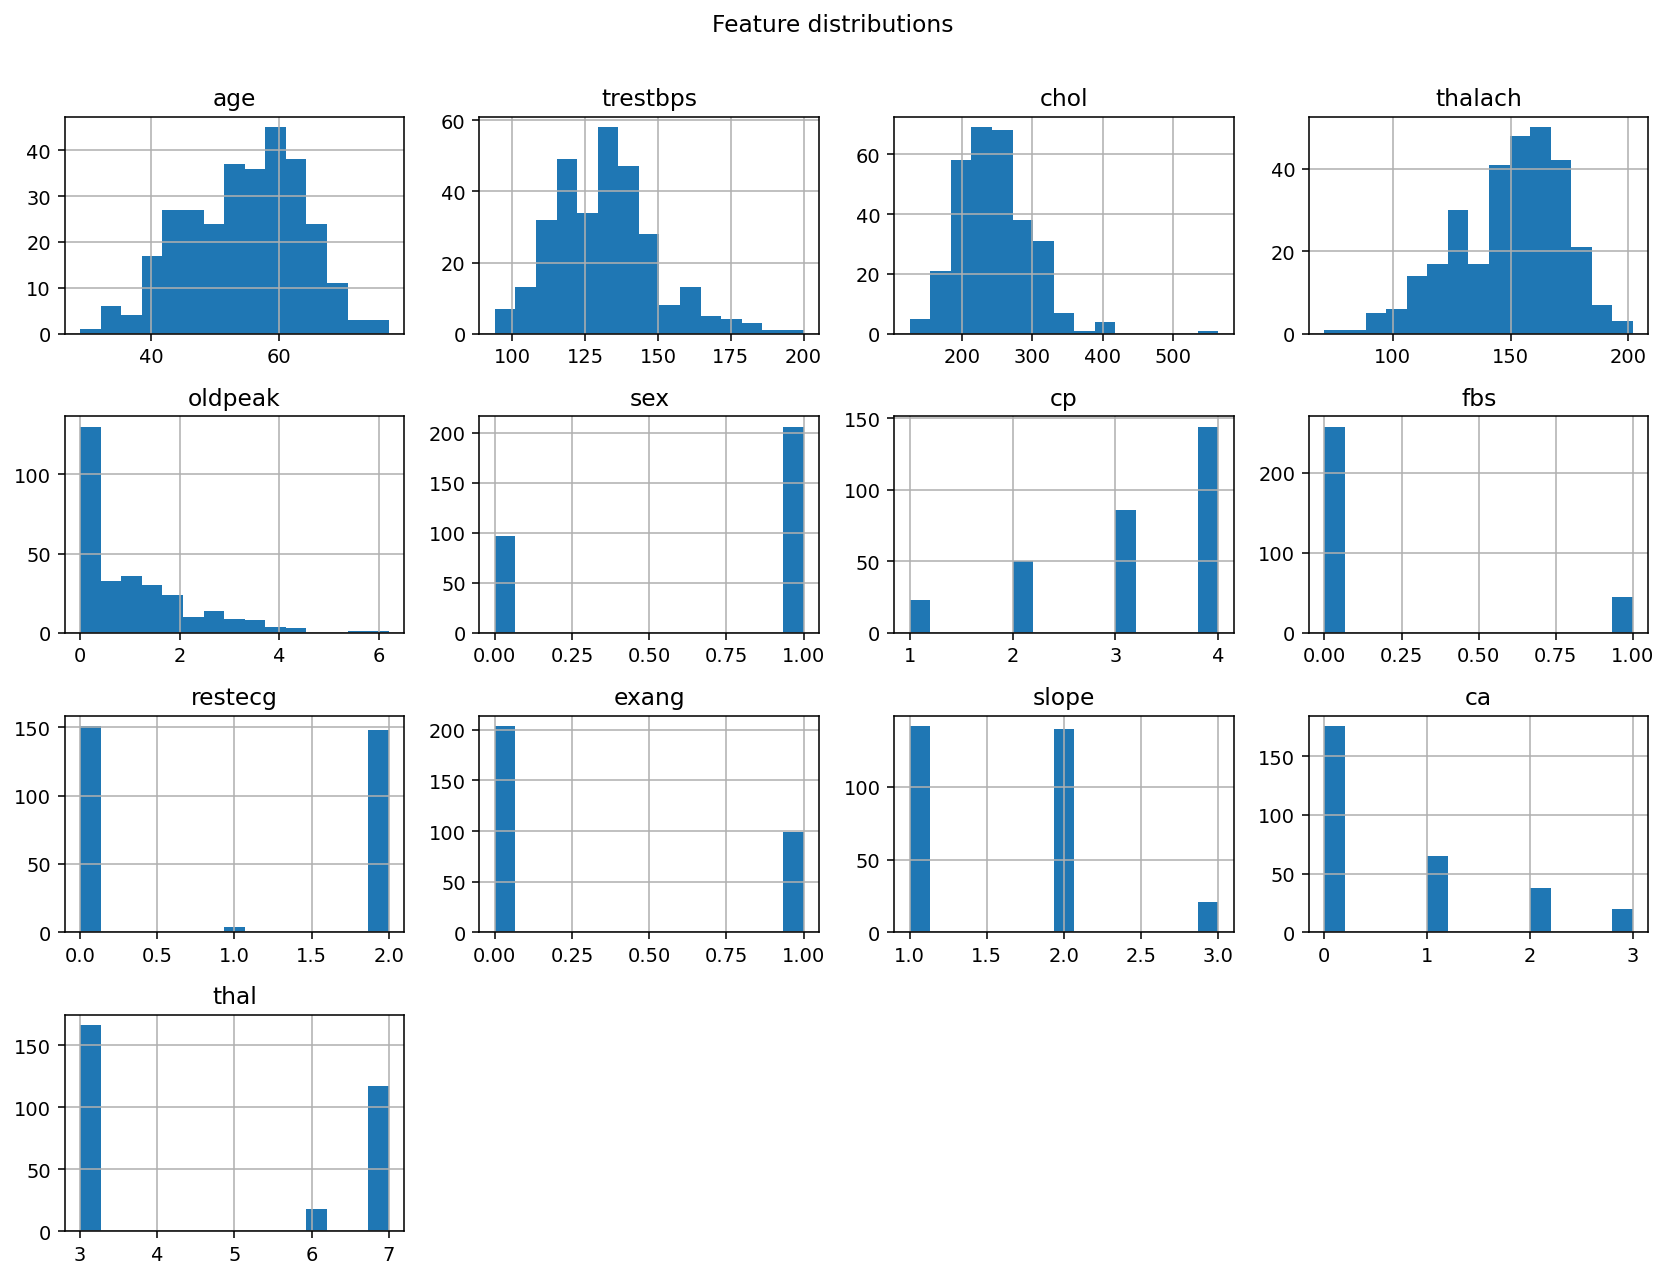

artifacts\correlation_heatmap.png


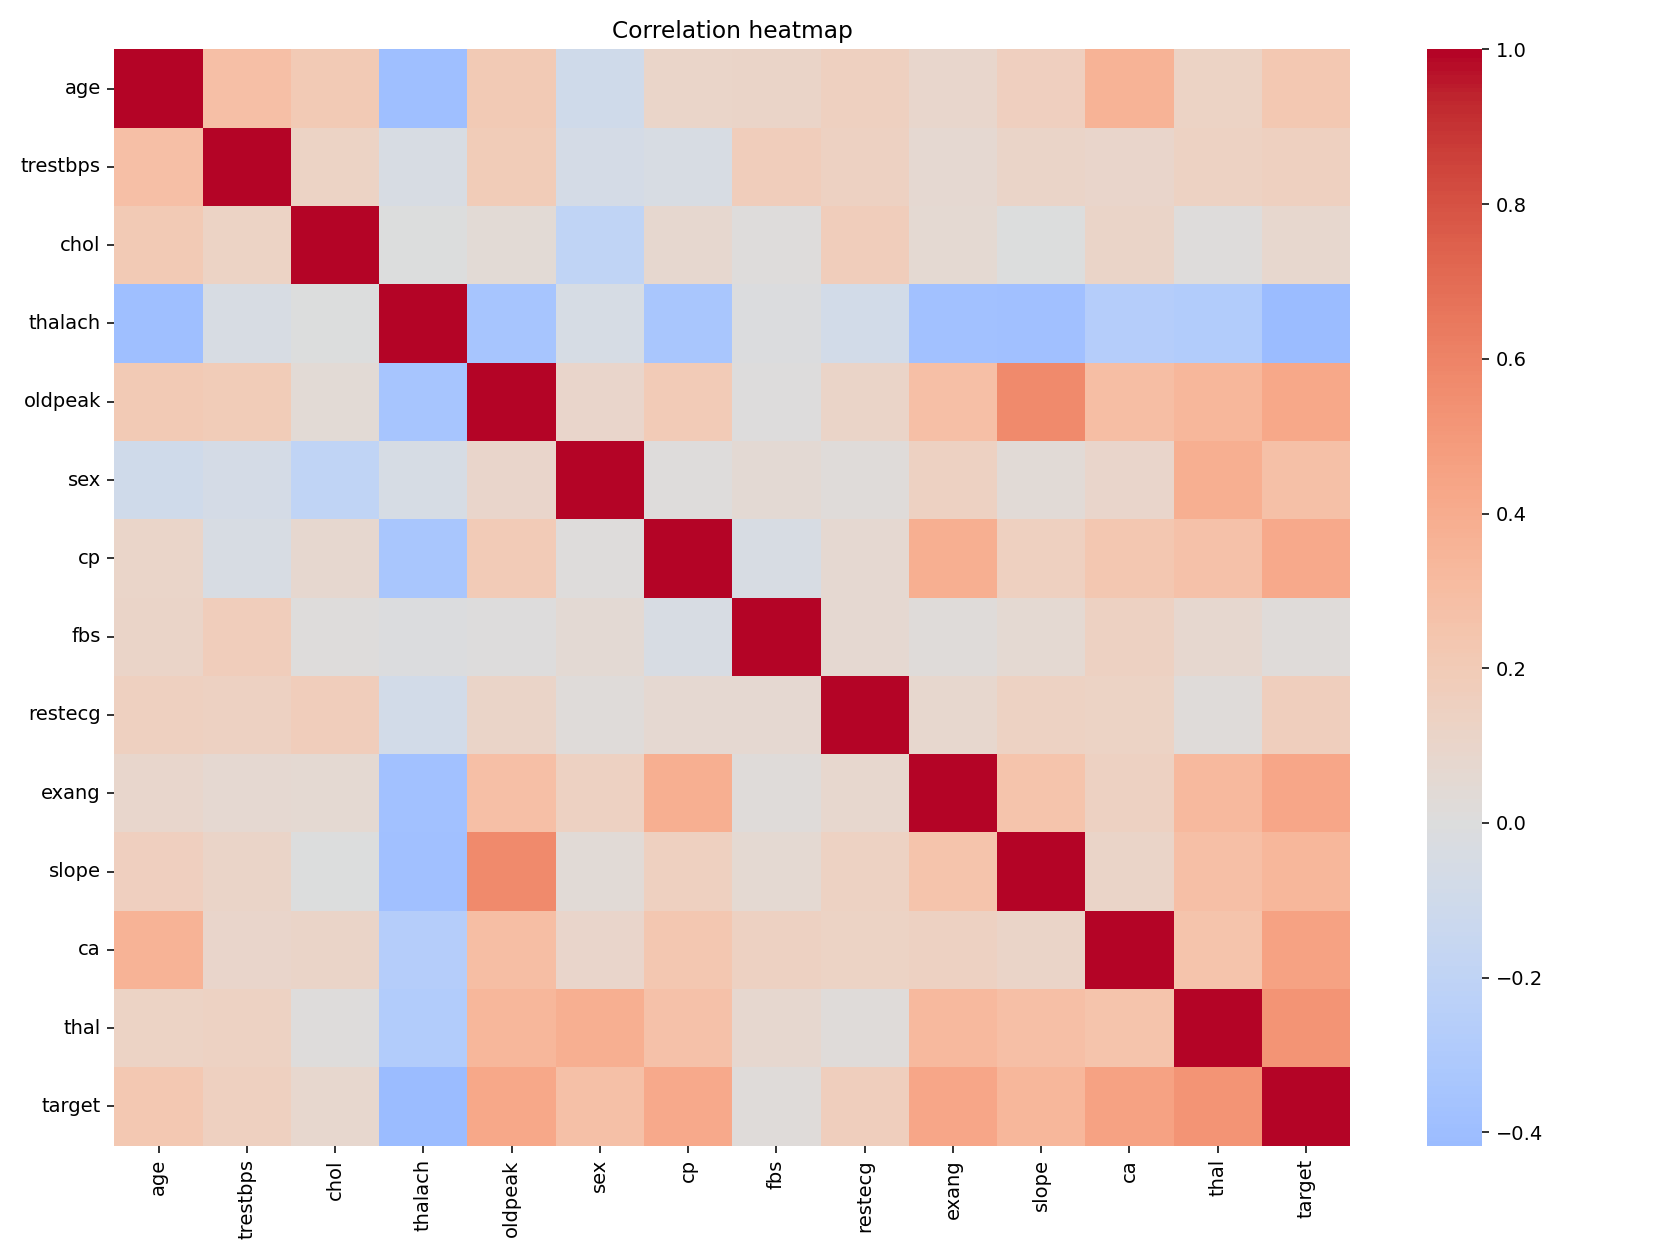

In [3]:
from pathlib import Path
from IPython.display import Image, display
from heartml.modeling import create_eda_artifacts
for path in create_eda_artifacts(df, "artifacts"):
    print(path)
    display(Image(filename=str(path)))


In [4]:
#create a local SQLite database for MLflow
MLFLOW_DB = PROJECT_DIR / "mlflow.db"
tracking_uri = MLFLOW_DB.resolve().as_uri()

#Configure MLflow


## 3. Train and track experiments with MLflow

In [5]:
import os
from heartml.modeling import train_and_track
import mlflow
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
#tracking_uri = os.getenv("MLFLOW_TRACKING_URI", "file:./mlruns
mlflow.set_tracking_uri(tracking_uri)
result = train_and_track(df=df, tracking_uri=tracking_uri, output_dir="artifacts")
display(pd.DataFrame(result["results"]).sort_values("cv_roc_auc_mean", ascending=False))


              model  test_accuracy  test_precision  test_recall  test_roc_auc  cv_roc_auc_mean                           run_id
logistic_regression       0.868852         0.81250     0.928571      0.966450         0.902478 cef155d3602042c1b65aaceabffa5583
      random_forest       0.901639         0.84375     0.964286      0.950216         0.895453 a8ce6b255ad941e5a7fb62308fcade9c
Selected by mean CV ROC-AUC: logistic_regression
Saved model pipeline: C:\Users\rranj\MLOps_project\mlops_heart_disease_assignment_2\notebooks\artifacts\model.joblib


,model,test_accuracy,test_precision,test_recall,test_roc_auc,cv_roc_auc_mean,run_id
0,logistic_regression,0.868852,0.81250,0.928571,0.966450,0.902478,cef155d3602042c1b65aaceabffa5583
1,random_forest,0.901639,0.84375,0.964286,0.950216,0.895453,a8ce6b255ad941e5a7fb62308fcade9c


## 4. Inspect model artifact and metrics

In [6]:
import json, joblib
print(Path("artifacts/metrics_summary.json").read_text(encoding="utf-8"))
model = joblib.load("artifacts/model.joblib")
print(model)


{
  "selected_model": "logistic_regression",
  "results": [
    {
      "model": "logistic_regression",
      "test_accuracy": 0.8688524590163934,
      "test_precision": 0.8125,
      "test_recall": 0.9285714285714286,
      "test_roc_auc": 0.9664502164502166,
      "cv_roc_auc_mean": 0.9024779568257829,
      "run_id": "cef155d3602042c1b65aaceabffa5583"
    },
    {
      "model": "random_forest",
      "test_accuracy": 0.9016393442622951,
      "test_precision": 0.84375,
      "test_recall": 0.9642857142857143,
      "test_roc_auc": 0.9502164502164503,
      "cv_roc_auc_mean": 0.8954528563224216,
      "run_id": "a8ce6b255ad941e5a7fb62308fcade9c"
    }
  ]
}
Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                          

## 5. Example prediction

In [7]:
# Synthetic example values only; not a real patient record.
example = pd.DataFrame([{
    "age":58,"sex":1,"cp":4,"trestbps":130,"chol":250,"fbs":0,"restecg":0,
    "thalach":150,"exang":0,"oldpeak":1.0,"slope":2,"ca":0,"thal":3
}], columns=FEATURES)
print({"prediction":int(model.predict(example)[0]),
       "probability_disease_present":round(float(model.predict_proba(example)[0,1]),4),
       "notice":"Educational demonstration only; not a clinical diagnosis."})


{'prediction': 1, 'probability_disease_present': 0.5149, 'notice': 'Educational demonstration only; not a clinical diagnosis.'}


## 6. Tests

In [8]:
subprocess.run([sys.executable,"-m","pip","install","-q","pytest","ruff"],check=True)
subprocess.run([sys.executable,"-m","pytest","-q"],check=True)


CalledProcessError: Command '['C:\\Users\\rranj\\anaconda3\\python.exe', '-m', 'pytest', '-q']' returned non-zero exit status 5.

## 7. Docker Desktop and MLflow

- Local machine: run `docker compose up -d mlflow`; open http://localhost:5000.
- For local Jupyter, set `MLFLOW_TRACKING_URI=http://127.0.0.1:5000` before training.
- Colab cannot use your desktop's localhost. Keep `file:./mlruns` in Colab or configure a secured reachable MLflow server.
- After training, run `docker compose --profile serving up --build -d api`.
- Test `http://localhost:8000/health`, `/docs`, and `/metrics`.
- The API uses `artifacts/model.joblib`; it does not need the raw dataset.
- Kubernetes manifest is a starter; verify image availability and pod health before reporting success.